# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Matthew Calvario, Carter Shaffer, Michael Mitchell

**Date:** 11/16/2026

299 rows, 13 columns

Column types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

Missing values: 0
Duplicated rows: 0

Numeric summary:
                          count       mean       std      min       25%  \
age                       299.0      60.83     11.89     40.0      51.0   
anaemia                   299.0       0.43      0.50      0.0       0.0   
creatinine_phosphokinase  299.0     581.84    970.29     23.0     116.5   
diabetes                  299.0       0.42      0.49      0.0       0.0   
ejection_fraction         299.0      38.08     11.

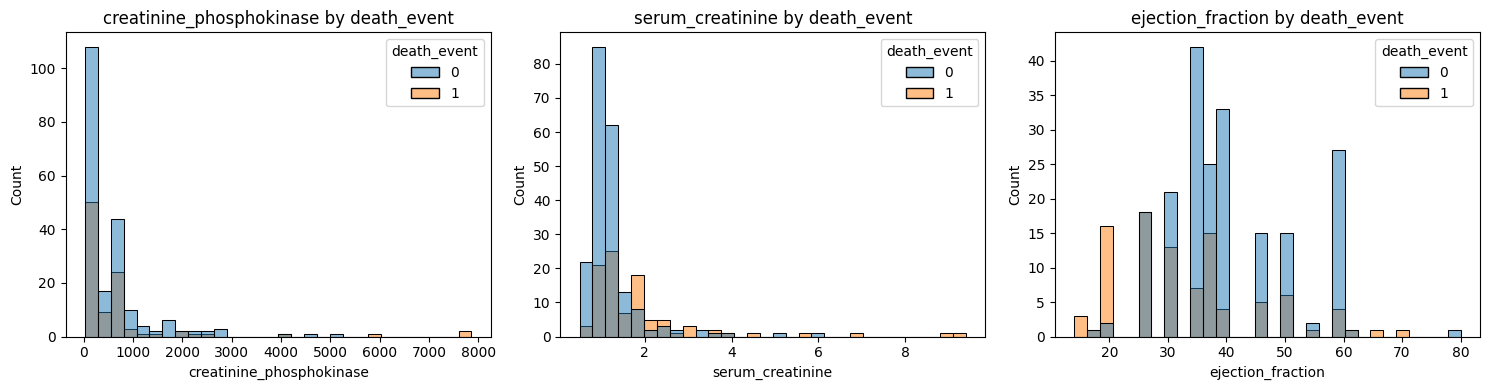

In [6]:
# Question 1 Solution

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('/content/heart_failure_clinical_records_dataset.csv')
print(f"{df.shape[0]} rows, {df.shape[1]} columns\n")
print("Column types:")
print(df.dtypes, "\n")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}\n")
print("Numeric summary:")
print(df.describe().T.round(2), "\n")

# Binary variables should only take the values 0 and 1
binary_vars = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]
for c in binary_vars:
    print(f"{c}: {sorted(df[c].unique())}")
print()

# Values that look like imputation or data entry artifacts
print(f"Non-integer ages: {sorted(df.loc[df['age'] % 1 != 0, 'age'].unique())}")
print(f"Rows with platelets = 263358.03 (the column mean): {(df['platelets'] == 263358.03).sum()}")
print(f"Rows with creatinine_phosphokinase = 582: {(df['creatinine_phosphokinase'] == 582).sum()}\n")

print("DEATH_EVENT share:")
print(df["DEATH_EVENT"].value_counts(normalize=True).round(3), "\n")

# Follow-up time is only known after the outcome happens
print("Mean follow-up time by outcome:")
print(df.groupby("DEATH_EVENT")["time"].mean().round(1), "\n")

print("Skewness:")
print(df[["creatinine_phosphokinase", "serum_creatinine", "platelets"]].skew().round(2), "\n")

# Cleaning: drop time (leakage), round age, rename target
hf = df.drop(columns="time").copy()
hf["age"] = hf["age"].round().astype(int)
hf = hf.rename(columns={"DEATH_EVENT": "death_event"})

y = hf["death_event"]
X = hf.drop(columns="death_event")
print(f"Cleaned data: {X.shape[0]} rows, {X.shape[1]} features")
print("Features:", list(X.columns))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["creatinine_phosphokinase", "serum_creatinine", "ejection_fraction"]):
    sns.histplot(data=hf, x=c, hue="death_event", bins=30, ax=ax)
    ax.set_title(f"{c} by death_event")
plt.tight_layout()
plt.show()

The data has 299 patients and 13 columns, all numeric, with no missing values or duplicates. The binary variables only take 0 and 1, so nothing needs recoding. We rounded two ages stored as 60.667 to 61. Some values appear to be mean-imputed by the original authors (25 platelet values of exactly 263,358.03 and 47 creatinine phosphokinase values of 582), but we kept these rows since the true values can’t be recovered. We dropped time because it leaks the outcome. Follow-up ends when a patient dies, so patients who died averaged 70.9 days compared with 158.3 for survivors. Creatinine phosphokinase and serum creatinine are heavily right-skewed (skewness of 4.46), but we left them untransformed since trees aren’t affected by skew. The histograms show deaths concentrated among patients with low ejection fraction and with serum creatinine above about 2. About 32.1% of patients died, so we stratify our splits to keep that share consistent.

In [7]:
# Question 2 Solution

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, roc_auc_score

# 80/20 split with a saved seed
main_seed = 125
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=main_seed, stratify=y
)
print(f"Seed {main_seed}: {len(X_train)} training rows, {len(X_test)} test rows\n")

# Choose tree complexity once with cross-validation, then hold it fixed for every seed
grid = GridSearchCV(
    DecisionTreeRegressor(random_state=0),
    {"max_depth": range(1, 9), "min_samples_leaf": [5, 10, 20]},
    cv=5, scoring="neg_mean_squared_error"
).fit(X_train, y_train)
tree_params = grid.best_params_
print(f"Tree settings chosen by 5-fold CV: {tree_params}\n")

def fit_models(X_tr, y_tr):
    tree = DecisionTreeRegressor(random_state=0, **tree_params).fit(X_tr, y_tr)
    # Standardize so coefficients are comparable (effect of a 1 SD change)
    lm = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
    return tree, lm

def evaluate(model, X_te, y_te):
    p = model.predict(X_te)
    return {"RMSE": np.sqrt(mean_squared_error(y_te, p)),
            "R^2": r2_score(y_te, p),
            "Accuracy": accuracy_score(y_te, p >= 0.5),
            "AUC": roc_auc_score(y_te, p)}

tree_main, lm_main = fit_models(X_train, y_train)

results = pd.DataFrame({"Tree": evaluate(tree_main, X_test, y_test),
                        "Linear": evaluate(lm_main, X_test, y_test)}).T
print(f"Test performance, seed {main_seed}:")
print(results.round(3), "\n")

# Set aside the test-set predictions
pred_tree_main = tree_main.predict(X_test)
pred_lm_main = lm_main.predict(X_test)

print(f"Tree (seed {main_seed}):")
print(export_text(tree_main, feature_names=list(X.columns), decimals=2))

coefs_main = pd.Series(lm_main[-1].coef_, index=X.columns)
print("Linear model coefficients (per 1 SD change in the feature):")
print(coefs_main.round(4))

Seed 125: 239 training rows, 60 test rows

Tree settings chosen by 5-fold CV: {'max_depth': 2, 'min_samples_leaf': 20}

Test performance, seed 125:
         RMSE    R^2  Accuracy    AUC
Tree    0.448  0.071      0.70  0.643
Linear  0.446  0.081      0.75  0.706 

Tree (seed 125):
|--- ejection_fraction <= 27.50
|   |--- ejection_fraction <= 22.50
|   |   |--- value: [0.86]
|   |--- ejection_fraction >  22.50
|   |   |--- value: [0.55]
|--- ejection_fraction >  27.50
|   |--- serum_creatinine <= 1.81
|   |   |--- value: [0.15]
|   |--- serum_creatinine >  1.81
|   |   |--- value: [0.71]

Linear model coefficients (per 1 SD change in the feature):
age                         0.0841
anaemia                     0.0043
creatinine_phosphokinase    0.0347
diabetes                    0.0000
ejection_fraction          -0.1480
high_blood_pressure         0.0464
platelets                   0.0086
serum_creatinine            0.1034
serum_sodium               -0.0632
sex                        -0.0

We used an 80/20 split with seed 125, stratified on the outcome, giving 239 training and 60 test patients. Both models predict the 0/1 outcome directly, so their predictions work as estimated death probabilities. Five-fold cross-validation on the training data chose a tree with a max depth of 2 and at least 20 patients per leaf, and we hold those settings fixed across all seeds so that differences between trees come from the data, not from tuning. The linear model uses standardized features, so each coefficient is the change in predicted death probability from a one standard deviation change in that feature. The two models perform similarly on the test set. The tree has an RMSE of 0.448, R² of 0.071, and 70% accuracy, and the linear model has an RMSE of 0.446, R² of 0.081, and 75% accuracy. Both models rely on the same signal. The tree splits first on ejection fraction at 27.5% and then on serum creatinine at 1.81, and the largest linear coefficients are ejection fraction (-0.148) and serum creatinine (0.103).

In [8]:
# Question 3 Solution

alt_seeds = [1, 22, 333, 4444]
trees, lms = {main_seed: tree_main}, {main_seed: lm_main}
own_preds = {main_seed: {"Tree": pred_tree_main, "Linear": pred_lm_main}}
perf_rows = [{"seed": main_seed, "model": m, **evaluate(mod, X_test, y_test)}
             for m, mod in [("Tree", tree_main), ("Linear", lm_main)]]

for s in alt_seeds:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    trees[s], lms[s] = fit_models(X_tr, y_tr)
    # Set aside each seed's predictions on its own test set
    own_preds[s] = {"Tree": trees[s].predict(X_te), "Linear": lms[s].predict(X_te)}
    for m, mod in [("Tree", trees[s]), ("Linear", lms[s])]:
        perf_rows.append({"seed": s, "model": m, **evaluate(mod, X_te, y_te)})

print("Test performance on each seed's own test set:")
print(pd.DataFrame(perf_rows).pivot(index="seed", columns="model").round(3), "\n")

for s in alt_seeds:
    print(f"Tree (seed {s}):")
    print(export_text(trees[s], feature_names=list(X.columns), decimals=2))

imp = pd.DataFrame({s: t.feature_importances_ for s, t in trees.items()}, index=X.columns)
print("Tree feature importances by seed:")
print(imp.round(3), "\n")

coefs = pd.DataFrame({s: m[-1].coef_ for s, m in lms.items()}, index=X.columns)
coefs["mean"] = coefs[list(lms)].mean(axis=1)
coefs["std"] = coefs[list(lms)].std(axis=1)
print("Linear model coefficients by seed (per 1 SD change in the feature):")
print(coefs.round(4))

Test performance on each seed's own test set:
        RMSE           R^2        Accuracy           AUC       
model Linear   Tree Linear   Tree   Linear   Tree Linear   Tree
seed                                                           
1      0.459  0.493  0.027 -0.121    0.700  0.650  0.644  0.554
22     0.407  0.416  0.236  0.200    0.800  0.750  0.829  0.748
125    0.446  0.448  0.081  0.071    0.750  0.700  0.706  0.643
333    0.424  0.412  0.170  0.215    0.667  0.733  0.772  0.765
4444   0.436  0.420  0.123  0.184    0.750  0.733  0.770  0.734 

Tree (seed 1):
|--- serum_creatinine <= 1.81
|   |--- ejection_fraction <= 27.50
|   |   |--- value: [0.68]
|   |--- ejection_fraction >  27.50
|   |   |--- value: [0.14]
|--- serum_creatinine >  1.81
|   |--- serum_creatinine <= 2.25
|   |   |--- value: [0.90]
|   |--- serum_creatinine >  2.25
|   |   |--- value: [0.60]

Tree (seed 22):
|--- serum_creatinine <= 1.81
|   |--- ejection_fraction <= 27.50
|   |   |--- value: [0.63]
|   |--

We repeated Q2 with seeds 1, 22, 333, and 4444, keeping the same tree settings. The trees change noticeably. The seed 125 tree splits first on ejection fraction, but all four alternative trees split first on serum creatinine, three at 1.81 and one (seed 333) at 1.45. The lower splits also shift. Seeds 22 and 4444 have only three leaves, seed 4444 moves the ejection fraction cutoff from 27.5 to 32.5, and seed 333 is the only tree that uses serum sodium. The feature importances reflect this, with ejection fraction getting 0.603 of the importance at seed 125 but only 0.37 to 0.42 for the other seeds. The linear coefficients are much more stable. Every seed agrees on the sign and rough size of the main effects: ejection fraction ranges from -0.115 to -0.148, serum creatinine from 0.078 to 0.126, age from 0.084 to 0.124, and serum sodium from -0.042 to -0.063. Only weak predictors near zero, like diabetes, platelets, and smoking, flip sign across seeds.

Seed 1: 48 of the 60 Q2 test patients were in its training set
Seed 22: 50 of the 60 Q2 test patients were in its training set
Seed 333: 46 of the 60 Q2 test patients were in its training set
Seed 4444: 49 of the 60 Q2 test patients were in its training set



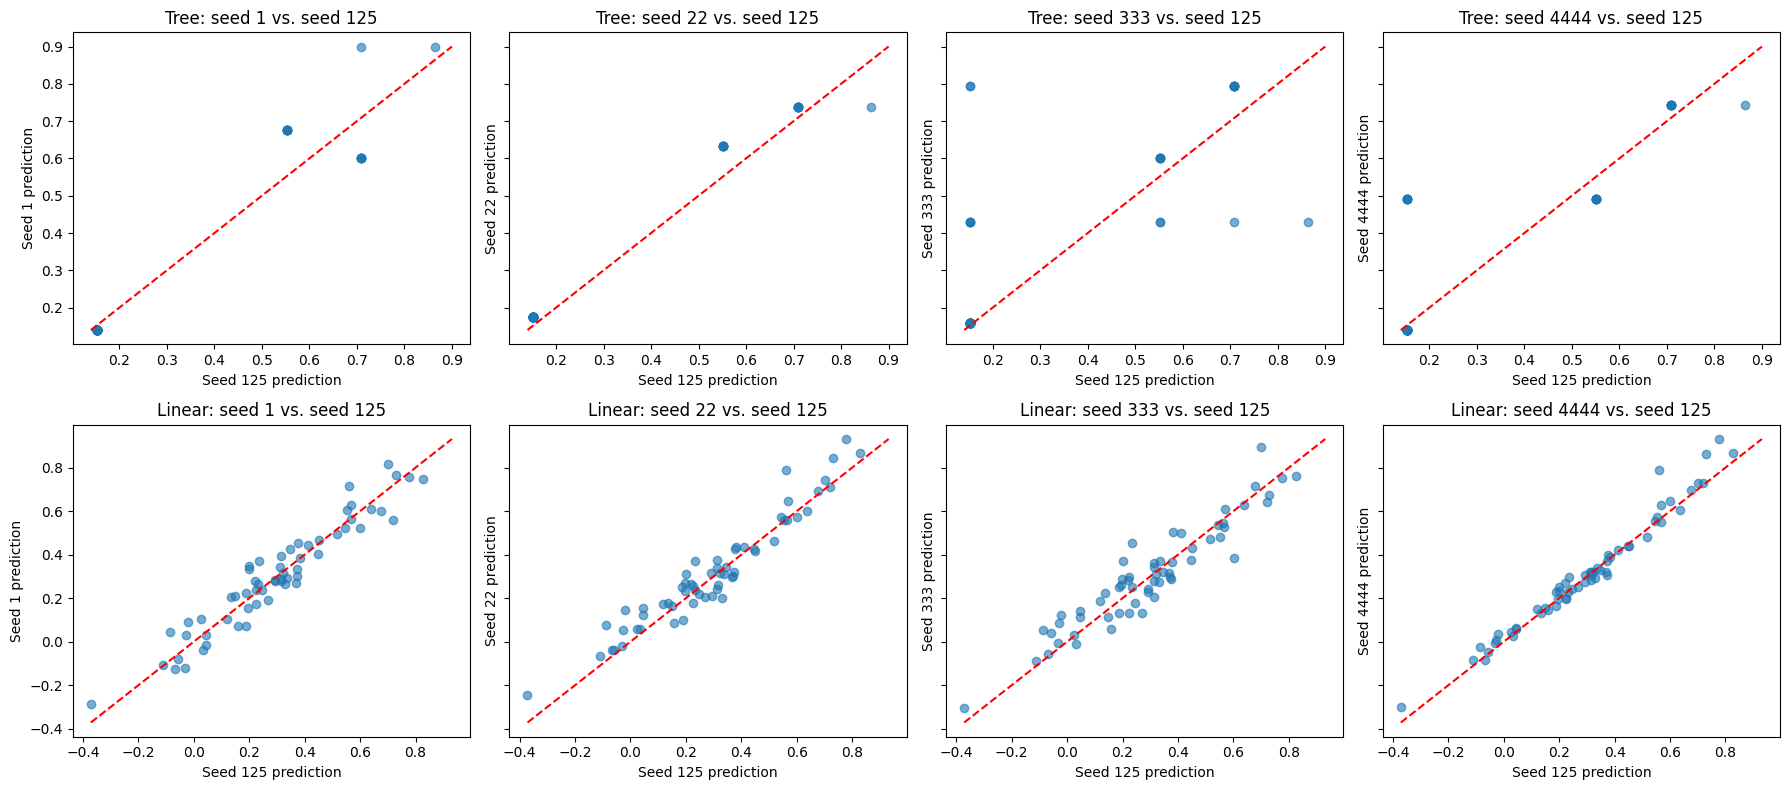

Tree predictions, seed 125 (rows) vs. seed 1 (columns):
1     0.14  0.60  0.68  0.90
125                         
0.15    45     0     0     0
0.55     0     0     7     0
0.71     0     6     0     1
0.86     0     0     0     1 

Tree predictions, seed 125 (rows) vs. seed 22 (columns):
22    0.18  0.63  0.74
125                   
0.15    45     0     0
0.55     0     7     0
0.71     0     0     7
0.86     0     0     1 

Tree predictions, seed 125 (rows) vs. seed 333 (columns):
333   0.16  0.43  0.60  0.79
125                         
0.15    39     4     0     2
0.55     0     2     5     0
0.71     0     1     0     6
0.86     0     1     0     0 

Tree predictions, seed 125 (rows) vs. seed 4444 (columns):
4444  0.14  0.49  0.74
125                   
0.15    39     6     0
0.55     0     7     0
0.71     0     0     7
0.86     0     0     1 

Correlation with seed 125 predictions:
           Tree  Linear
alt seed               
1         0.967   0.957
22        0.993   0.959
333

In [9]:
# Question 4 Solution

# Every model predicts the same 60 patients: the seed 125 test set from Q2
preds = {
    "Tree": pd.DataFrame({s: t.predict(X_test) for s, t in trees.items()}, index=X_test.index),
    "Linear": pd.DataFrame({s: m.predict(X_test) for s, m in lms.items()}, index=X_test.index)
}

# Overlap between the Q2 test set and each alternative training set
for s in alt_seeds:
    X_tr, _, _, _ = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    print(f"Seed {s}: {X_test.index.isin(X_tr.index).sum()} of the {len(X_test)} "
          f"Q2 test patients were in its training set")
print()

# 4a. Scatterplots of alternative predictions vs. Q2 predictions
fig, axes = plt.subplots(2, len(alt_seeds), figsize=(18, 8), sharex="row", sharey="row")
for r, m in enumerate(["Tree", "Linear"]):
    p = preds[m]
    for ax, s in zip(axes[r], alt_seeds):
        ax.scatter(p[main_seed], p[s], alpha=0.6)
        lo, hi = p.min().min(), p.max().max()
        ax.plot([lo, hi], [lo, hi], color="red", linestyle="--")
        ax.set(title=f"{m}: seed {s} vs. seed {main_seed}",
               xlabel=f"Seed {main_seed} prediction", ylabel=f"Seed {s} prediction")
plt.tight_layout()
plt.show()

# Trees only produce a few distinct values, so many points stack on top of each other
for s in alt_seeds:
    print(f"Tree predictions, seed {main_seed} (rows) vs. seed {s} (columns):")
    print(pd.crosstab(preds["Tree"][main_seed].round(2), preds["Tree"][s].round(2)), "\n")

# 4b. Correlations with the Q2 model
corr = pd.DataFrame({m: preds[m].corr().loc[main_seed, alt_seeds] for m in ["Tree", "Linear"]})
corr.index.name = "alt seed"
print(f"Correlation with seed {main_seed} predictions:")
print(corr.round(3))
print(f"Average: Tree {corr['Tree'].mean():.3f}, Linear {corr['Linear'].mean():.3f}\n")

# 4c. Regress alternative predictions on the Q2 predictions
rows = []
for m in ["Tree", "Linear"]:
    base = preds[m][[main_seed]].to_numpy()
    for s in alt_seeds:
        reg = LinearRegression().fit(base, preds[m][s])
        rows.append({"model": m, "alt seed": s, "intercept": reg.intercept_,
                     "slope": reg.coef_[0], "R^2": reg.score(base, preds[m][s])})
print(f"Regression of alternative predictions on seed {main_seed} predictions:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Coefficient variability relative to size
print("\nLinear coefficient std / |mean|:")
print((coefs["std"] / coefs["mean"].abs()).round(2).sort_values())

Linear coefficients: The coefficients don’t all vary by the same amount. The strong predictors stay pretty steady across seeds. For ejection fraction, age, serum sodium, and serum creatinine, the standard deviation is only about 12 to 18% of the average coefficient. The weak predictors are a different story. For diabetes, platelets, and smoking, the standard deviation is 4 to 15 times the size of the coefficient itself. Their true effects are basically zero, so just reshuffling which patients end up in training is enough to flip their signs.

4a. We had every model predict the same 60 patients from the Q2 test set. Most of those patients (46 to 50) were also in the alternative models’ training data, so the comparison isn’t perfectly clean. The linear plots look like tight clouds along the 45-degree line. The tree plots look more like grids, since each tree only gives 3 or 4 possible predictions and a lot of points stack on top of each other. Even so, most patients land on or near the line. All 45 patients the seed 125 tree puts at 0.15 get 0.14 from the seed 1 tree, even though that tree starts with a completely different split. Seed 333 is the biggest outlier: 6 of those 45 low-risk patients get bumped up to 0.43 or 0.79. Overall, the predictions look reasonably similar for both models, but the linear models are clearly closer.

4b. Both sets of models are highly correlated with their Q2 versions. The linear models are the most consistent, with correlations between 0.940 and 0.983 (average 0.960). The trees average 0.904 but swing more, from 0.993 for seed 22 down to 0.778 for seed 333. That low one makes sense because seed 333 is the only tree that splits on serum sodium.

4c. The intercepts are all close to zero (-0.013 to 0.086) and the slopes are close to 1 (0.833 to 1.045). So the alternative models aren’t just shifted or stretched versions of the original. They’re predicting about the same values. R² is high across the board for the linear models (0.884 to 0.967). For the trees it depends on the seed: 0.985 and 0.935 for seeds 22 and 1, but only 0.773 and 0.605 for seeds 4444 and 333. That lines up with 4b, since R² in a simple regression is just the correlation squared.

**Question 5 Solution**

Yes for linear models, and only partly for trees. Across all five seeds, the linear models kept the same signs and similar sizes for every meaningful coefficient. Only the near-zero ones, like smoking and platelets, bounced around. Their predictions stayed tightly correlated too, between 0.94 and 0.98. The trees were a different story. Four of the five picked a different first split than the Q2 tree, the cutoffs moved around, the number of leaves changed, and one tree pulled in serum sodium out of nowhere. Small changes in the training data can change which split looks best at the top, and everything below it changes with it. Their predictions held up better than their structure (average correlation of 0.904), but they were still less consistent than the linear models, dropping as low as 0.778. Both models ended up finding the same basic signal: low ejection fraction and high serum creatinine mean higher risk. The linear model just expresses it in a smoother, more stable way.

**Question 6 Solution**

True, for the most part. The trees looked very different from each other: four of the five started with a different root split than the Q2 tree, and the cutoffs, depth, and features used all changed. Even so, their predictions on the same patients were correlated between 0.78 and 0.99 with the Q2 tree, with slopes near 1 and intercepts near 0. Seed 1 is the best example. That tree splits on serum creatinine first instead of ejection fraction, but its predictions still have a 0.967 correlation with the Q2 tree. Ejection fraction and serum creatinine carry most of the signal, so different trees can combine them in a different order and still sort patients into roughly the same risk groups. The linear models show the same pattern: their weak coefficients flip signs, yet their predictions stay correlated above 0.94. The word “often” matters here, though. The seed 333 tree, which brought in serum sodium, only reached a 0.778 correlation and an R² of 0.605, so different-looking models don’t always produce the same predictions. Overall, judging a model’s stability by its structure overstates how much its predictions actually change.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 67133aa8194032705467fb36f518109486c55a9e
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Examine the python notebook I have attached. I want you to suggest any improvements,optimizations, or general reccomendations to improve the quality of this lab submission. I have attached the necessary data files below as well. Only look at the phase 1, and suggest from there.


### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Your main conclusion depends on the tree depth you chose

CV picked max_depth=2, min_samples_leaf=20, which is a very stable tree. Shallow trees can only form 3 or 4 risk groups, so their predictions are bound to agree.
I fit fully grown trees on the same five seeds, and their prediction correlations with the seed 125 tree dropped to 0.03 to 0.24 (vs. your 0.78 to 0.99).
Why it matters: your Q6 “True” holds for pruned trees but not for trees in general. Adding a short unpruned-tree comparison would make Q5/Q6 much more convincing, and it’s exactly the instability the assignment is about.

2. The linear model’s “probabilities” go outside 0 to 1

You describe predictions as “estimated death probabilities,” but the seed 125 linear model predicts negative values for 30 of 299 patients and above 1 for 3 (similar for other seeds).
Options (trade-offs):
Keep LinearRegression (simplest, matches “linear model”) but reword to “predicted risk scores” and note the out-of-range values.
Clip predictions to [0, 1] (quick fix, slightly distorts 4b/4c).
Switch to LogisticRegression (proper probabilities, but coefficients are on the log-odds scale, so Q3 interpretation changes).

3. Add a baseline to the performance results

About 68.3% of the test patients survived, so always predicting “no death” gives 68.3% accuracy. Your tree’s 70% barely beats that.
Add one line reporting the majority-class baseline, and mention in Q2 that R² values of 0.07 to 0.08 mean both models are weak. This frames the stability discussion honestly: you’re comparing stability of models that explain little variance.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept  | The AI is correct that atting this change and clarification in Q6 is a great idea for a reliable solution. |
| 2 | Accept  | Rewording here clears up any confusion with the probabilities and is generally a best practice. |
| 3 | Accept  | A baseline is a great idea as it adds better context to the conclusion and improves the quality of this solution. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

299 rows, 13 columns

Column types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

Missing values: 0
Duplicated rows: 0

Numeric summary:
                          count       mean       std      min       25%  \
age                       299.0      60.83     11.89     40.0      51.0   
anaemia                   299.0       0.43      0.50      0.0       0.0   
creatinine_phosphokinase  299.0     581.84    970.29     23.0     116.5   
diabetes                  299.0       0.42      0.49      0.0       0.0   
ejection_fraction         299.0      38.08     11.

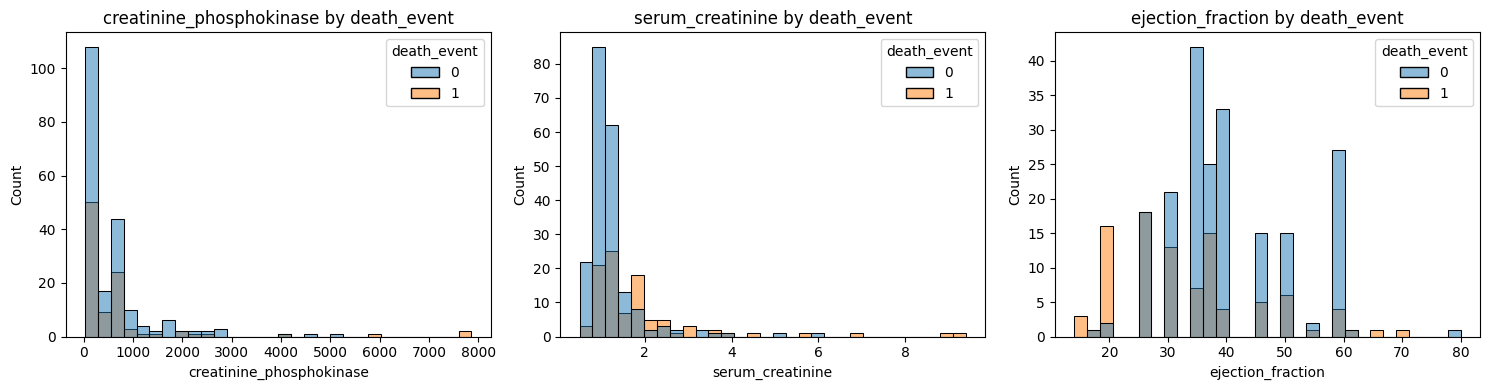

Seed 125: 239 training rows, 60 test rows

Tree settings chosen by 5-fold CV: {'max_depth': 2, 'min_samples_leaf': 20}

Test performance, seed 125:
           RMSE    R^2  Accuracy    AUC
Baseline  0.465 -0.000     0.683  0.500
Tree      0.448  0.071     0.700  0.643
Linear    0.446  0.081     0.750  0.706 

Linear risk scores on all 299 patients range from -0.371 to 1.453
Below 0: 30 patients, above 1: 3 patients

Tree (seed 125):
|--- ejection_fraction <= 27.50
|   |--- ejection_fraction <= 22.50
|   |   |--- value: [0.86]
|   |--- ejection_fraction >  22.50
|   |   |--- value: [0.55]
|--- ejection_fraction >  27.50
|   |--- serum_creatinine <= 1.81
|   |   |--- value: [0.15]
|   |--- serum_creatinine >  1.81
|   |   |--- value: [0.71]

Linear model coefficients (per 1 SD change in the feature):
age                         0.0841
anaemia                     0.0043
creatinine_phosphokinase    0.0347
diabetes                    0.0000
ejection_fraction          -0.1480
high_blood_press

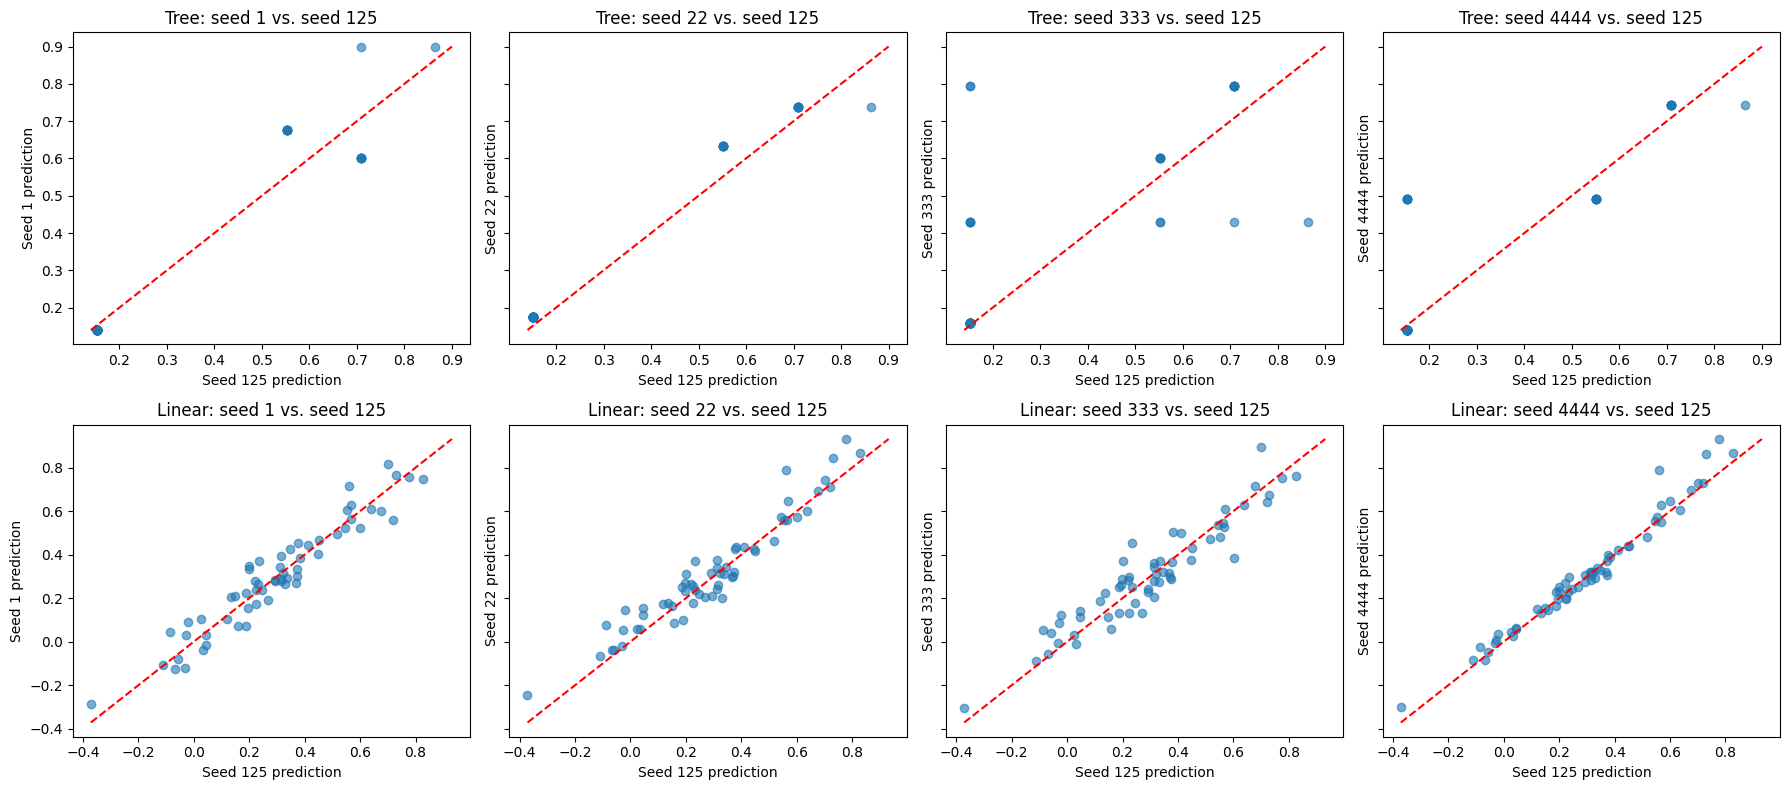

Tree predictions, seed 125 (rows) vs. seed 1 (columns):
1     0.14  0.60  0.68  0.90
125                         
0.15    45     0     0     0
0.55     0     0     7     0
0.71     0     6     0     1
0.86     0     0     0     1 

Tree predictions, seed 125 (rows) vs. seed 22 (columns):
22    0.18  0.63  0.74
125                   
0.15    45     0     0
0.55     0     7     0
0.71     0     0     7
0.86     0     0     1 

Tree predictions, seed 125 (rows) vs. seed 333 (columns):
333   0.16  0.43  0.60  0.79
125                         
0.15    39     4     0     2
0.55     0     2     5     0
0.71     0     1     0     6
0.86     0     1     0     0 

Tree predictions, seed 125 (rows) vs. seed 4444 (columns):
4444  0.14  0.49  0.74
125                   
0.15    39     6     0
0.55     0     7     0
0.71     0     0     7
0.86     0     0     1 

Correlation with seed 125 predictions:
           Tree  Linear
alt seed               
1         0.967   0.957
22        0.993   0.959
333

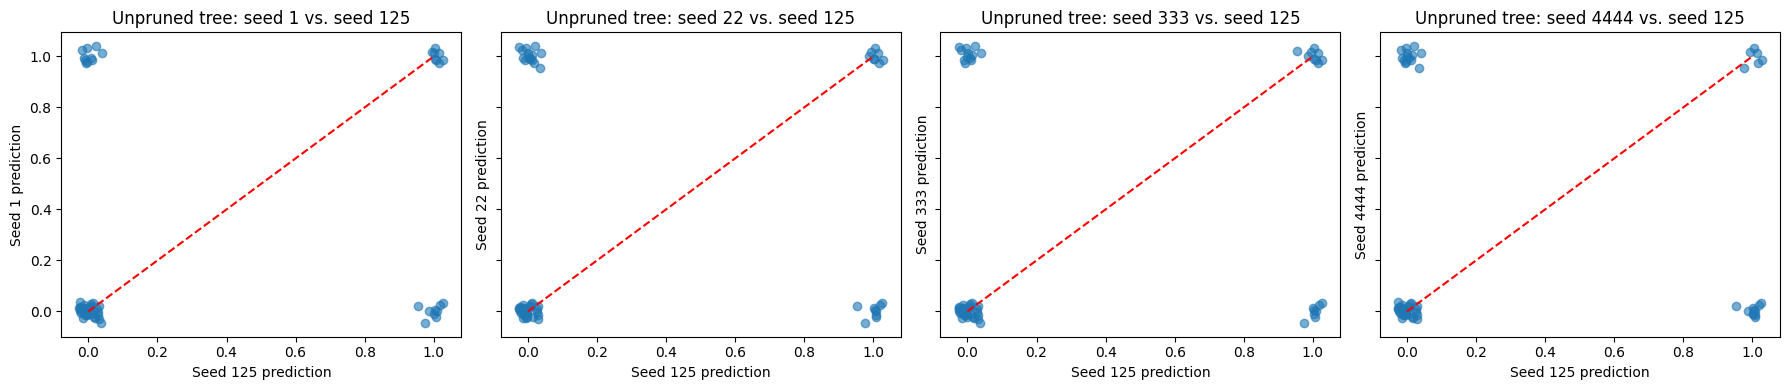

Unpruned tree correlation with seed 125:
1       0.234
22      0.113
333     0.237
4444    0.026
Name: 125, dtype: float64
Average: 0.152

Unpruned tree regression on seed 125 predictions:
 alt seed  intercept  slope   R^2
        1      0.233  0.238 0.055
       22      0.349  0.122 0.013
      333      0.279  0.250 0.056
     4444      0.326  0.027 0.001 

Share of the 60 patients classified the same as seed 125 (0.5 threshold):
           Tree  Linear  Unpruned tree
alt seed                              
1         1.000   0.983          0.683
22        1.000   0.983          0.600
333       0.900   0.917          0.667
4444      0.883   0.983          0.583
Seed 1 unpruned tree returns the exact outcome for 100% of overlapping patients
Seed 22 unpruned tree returns the exact outcome for 100% of overlapping patients
Seed 333 unpruned tree returns the exact outcome for 100% of overlapping patients
Seed 4444 unpruned tree returns the exact outcome for 100% of overlapping patients

Corr

In [10]:
# =====================================================================
# Phase 2 Solution (AI-assisted revision)
# Accepted revisions:
#   1. Added an unpruned-tree comparison (Q3, Q4d, Q5, Q6)
#   2. Linear predictions described as risk scores, out-of-range values reported (Q2, Q3)
#   3. Added a majority-class baseline to the performance results (Q2, Q3)
# =====================================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, roc_auc_score

# ---------------------------------------------------------------------
# Question 1: Explore and clean the data
# ---------------------------------------------------------------------

df = pd.read_csv('/content/heart_failure_clinical_records_dataset.csv')
print(f"{df.shape[0]} rows, {df.shape[1]} columns\n")
print("Column types:")
print(df.dtypes, "\n")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}\n")
print("Numeric summary:")
print(df.describe().T.round(2), "\n")

# Binary variables should only take the values 0 and 1
binary_vars = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]
for c in binary_vars:
    print(f"{c}: {sorted(df[c].unique())}")
print()

# Values that look like imputation or data entry artifacts
print(f"Non-integer ages: {sorted(df.loc[df['age'] % 1 != 0, 'age'].unique())}")
print(f"Rows with platelets = 263358.03 (the column mean): {(df['platelets'] == 263358.03).sum()}")
print(f"Rows with creatinine_phosphokinase = 582: {(df['creatinine_phosphokinase'] == 582).sum()}\n")

print("DEATH_EVENT share:")
print(df["DEATH_EVENT"].value_counts(normalize=True).round(3), "\n")

# Follow-up time is only known after the outcome happens
print("Mean follow-up time by outcome:")
print(df.groupby("DEATH_EVENT")["time"].mean().round(1), "\n")

print("Skewness:")
print(df[["creatinine_phosphokinase", "serum_creatinine", "platelets"]].skew().round(2), "\n")

# Cleaning: drop time (leakage), round age, rename target
hf = df.drop(columns="time").copy()
hf["age"] = hf["age"].round().astype(int)
hf = hf.rename(columns={"DEATH_EVENT": "death_event"})

y = hf["death_event"]
X = hf.drop(columns="death_event")
print(f"Cleaned data: {X.shape[0]} rows, {X.shape[1]} features")
print("Features:", list(X.columns))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["creatinine_phosphokinase", "serum_creatinine", "ejection_fraction"]):
    sns.histplot(data=hf, x=c, hue="death_event", bins=30, ax=ax)
    ax.set_title(f"{c} by death_event")
plt.tight_layout()
plt.show()

# Written answer (Q1):
# The data has 299 patients and 13 columns, all numeric, with no missing values or
# duplicates. The binary variables only take 0 and 1, so nothing needs recoding. We
# rounded two ages stored as 60.667 to 61. Some values appear to be mean-imputed by the
# original authors (25 platelet values of exactly 263,358.03 and 47 creatinine
# phosphokinase values of 582), but we kept these rows since the true values can't be
# recovered. We dropped time because it leaks the outcome. Follow-up ends when a patient
# dies, so patients who died averaged 70.9 days compared with 158.3 for survivors.
# Creatinine phosphokinase and serum creatinine are both heavily right-skewed (skewness
# of about 4.46 each), but we left them untransformed since trees aren't affected by
# skew. The histograms show deaths concentrated among patients with low ejection
# fraction and with serum creatinine above about 2. About 32.1% of patients died, so we
# stratify our splits to keep that share consistent.

# ---------------------------------------------------------------------
# Question 2: One split, fit a tree and a linear model
# ---------------------------------------------------------------------

# 80/20 split with a saved seed
main_seed = 125
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=main_seed, stratify=y
)
print(f"Seed {main_seed}: {len(X_train)} training rows, {len(X_test)} test rows\n")

# Choose tree complexity once with cross-validation, then hold it fixed for every seed
grid = GridSearchCV(
    DecisionTreeRegressor(random_state=0),
    {"max_depth": range(1, 9), "min_samples_leaf": [5, 10, 20]},
    cv=5, scoring="neg_mean_squared_error"
).fit(X_train, y_train)
tree_params = grid.best_params_
print(f"Tree settings chosen by 5-fold CV: {tree_params}\n")

def fit_models(X_tr, y_tr):
    tree = DecisionTreeRegressor(random_state=0, **tree_params).fit(X_tr, y_tr)
    # Standardize so coefficients are comparable (effect of a 1 SD change)
    lm = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
    # Majority-class baseline: always predicts the training death rate
    base = DummyRegressor(strategy="mean").fit(X_tr, y_tr)
    return tree, lm, base

def evaluate(model, X_te, y_te):
    p = model.predict(X_te)
    return {"RMSE": np.sqrt(mean_squared_error(y_te, p)),
            "R^2": r2_score(y_te, p),
            "Accuracy": accuracy_score(y_te, p >= 0.5),
            "AUC": roc_auc_score(y_te, p)}

tree_main, lm_main, base_main = fit_models(X_train, y_train)

results = pd.DataFrame({"Baseline": evaluate(base_main, X_test, y_test),
                        "Tree": evaluate(tree_main, X_test, y_test),
                        "Linear": evaluate(lm_main, X_test, y_test)}).T
print(f"Test performance, seed {main_seed}:")
print(results.round(3), "\n")

# Set aside the test-set predictions
pred_tree_main = tree_main.predict(X_test)
pred_lm_main = lm_main.predict(X_test)

# Linear predictions are risk scores, not true probabilities: check the range
lm_all = lm_main.predict(X)
print(f"Linear risk scores on all {len(X)} patients range from {lm_all.min():.3f} to {lm_all.max():.3f}")
print(f"Below 0: {(lm_all < 0).sum()} patients, above 1: {(lm_all > 1).sum()} patients\n")

print(f"Tree (seed {main_seed}):")
print(export_text(tree_main, feature_names=list(X.columns), decimals=2))

coefs_main = pd.Series(lm_main[-1].coef_, index=X.columns)
print("Linear model coefficients (per 1 SD change in the feature):")
print(coefs_main.round(4))

# Written answer (Q2):
# We used an 80/20 split with seed 125, stratified on the outcome, giving 239 training
# and 60 test patients. Both models predict the 0/1 outcome directly, so we treat their
# outputs as risk scores on the probability scale. They aren't true probabilities,
# though. The linear model gives 30 of the 299 patients a score below 0 and 3 a score
# above 1. We kept linear regression because the assignment asks for a linear model and
# its scores line up directly with the tree's, but out-of-range scores are a known
# weakness of using a linear model on a 0/1 outcome. Five-fold cross-validation on the
# training data chose a tree with a max depth of 2 and at least 20 patients per leaf, and
# we hold those settings fixed across all seeds so that differences between trees come
# from the data, not from tuning. The linear model uses standardized features, so each
# coefficient is the change in risk score from a one standard deviation change in that
# feature.
#
# To judge performance we added a baseline that always predicts the training death rate
# (about 0.32). That never reaches 0.5, so it labels every patient a survivor and gets
# 68.3% accuracy, an R^2 of 0, and an AUC of 0.5. Against that baseline, both models are
# weak. The tree has an RMSE of 0.448, R^2 of 0.071, 70% accuracy, and AUC of 0.643, so
# it classifies only one more patient correctly than the baseline. The linear model does
# a bit better, with an RMSE of 0.446, R^2 of 0.081, 75% accuracy, and AUC of 0.706. R^2
# values under 0.1 mean both models explain less than 10% of the variation in outcomes,
# so the stability comparisons below are between models that capture a real but modest
# signal. Both models rely on the same signal. The tree splits first on ejection
# fraction at 27.5% and then on serum creatinine at 1.81, and the largest linear
# coefficients are ejection fraction (-0.148) and serum creatinine (0.103).

# ---------------------------------------------------------------------
# Question 3: Repeat for four more seeds
# ---------------------------------------------------------------------

alt_seeds = [1, 22, 333, 4444]
all_seeds = [main_seed] + alt_seeds
splits = {main_seed: (X_train, X_test, y_train, y_test)}
trees, lms = {main_seed: tree_main}, {main_seed: lm_main}
own_preds = {main_seed: {"Tree": pred_tree_main, "Linear": pred_lm_main}}
perf_rows = [{"seed": main_seed, "model": m, **evaluate(mod, X_test, y_test)}
             for m, mod in [("Baseline", base_main), ("Tree", tree_main), ("Linear", lm_main)]]

for s in alt_seeds:
    splits[s] = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    X_tr, X_te, y_tr, y_te = splits[s]
    trees[s], lms[s], base_s = fit_models(X_tr, y_tr)
    # Set aside each seed's predictions on its own test set
    own_preds[s] = {"Tree": trees[s].predict(X_te), "Linear": lms[s].predict(X_te)}
    for m, mod in [("Baseline", base_s), ("Tree", trees[s]), ("Linear", lms[s])]:
        perf_rows.append({"seed": s, "model": m, **evaluate(mod, X_te, y_te)})

perf = pd.DataFrame(perf_rows)
print("Test performance on each seed's own test set:")
print(perf.pivot(index="seed", columns="model").round(3), "\n")

for s in alt_seeds:
    print(f"Tree (seed {s}):")
    print(export_text(trees[s], feature_names=list(X.columns), decimals=2))

imp = pd.DataFrame({s: t.feature_importances_ for s, t in trees.items()}, index=X.columns)
print("Tree feature importances by seed:")
print(imp.round(3), "\n")

coefs = pd.DataFrame({s: m[-1].coef_ for s, m in lms.items()}, index=X.columns)
coefs["mean"] = coefs[all_seeds].mean(axis=1)
coefs["std"] = coefs[all_seeds].std(axis=1)
print("Linear model coefficients by seed (per 1 SD change in the feature):")
print(coefs.round(4), "\n")

# Out-of-range linear risk scores for every seed
for s, m in lms.items():
    p = m.predict(X)
    print(f"Seed {s}: {(p < 0).sum()} linear scores below 0, {(p > 1).sum()} above 1")
print()

# Unpruned trees: same seeds, no depth or leaf-size limits
full_trees = {s: DecisionTreeRegressor(random_state=0).fit(splits[s][0], splits[s][2])
              for s in all_seeds}
print("Unpruned tree structure by seed:")
print(pd.DataFrame({s: {"depth": t.get_depth(), "leaves": t.get_n_leaves(),
                        "root split": X.columns[t.tree_.feature[0]]}
                    for s, t in full_trees.items()}).T, "\n")

# Written answer (Q3):
# We repeated Q2 with seeds 1, 22, 333, and 4444, keeping the same tree settings.
# Performance moves around with the split. The baseline is 68.3% on every seed because
# the splits are stratified, and neither model beats it every time. Tree accuracy ranges
# from 65% to 75% and linear accuracy from 66.7% to 80%. The seed 1 tree (65%, R^2 of
# -0.121) and the seed 333 linear model (66.7%) both do worse than the baseline. Every
# seed's linear model still produces out-of-range scores (21 to 30 below 0 and 2 to 5
# above 1 across the full data).
#
# The trees change noticeably. The seed 125 tree splits first on ejection fraction, but
# all four alternative trees split first on serum creatinine, three at 1.81 and one
# (seed 333) at 1.45. The lower splits also shift. Seeds 22 and 4444 have only three
# leaves, seed 4444 moves the ejection fraction cutoff from 27.5 to 32.5, and seed 333 is
# the only tree that uses serum sodium. The feature importances reflect this, with
# ejection fraction getting 0.603 of the importance at seed 125 but only 0.37 to 0.42 for
# the other seeds. Unpruned trees change far more. They grow to depths of 11 to 18 with
# 47 to 53 leaves, so even their size differs by seed.
#
# The linear coefficients are much more stable. Every seed agrees on the sign and rough
# size of the main effects: ejection fraction ranges from -0.115 to -0.148, serum
# creatinine from 0.078 to 0.126, age from 0.084 to 0.124, and serum sodium from -0.042
# to -0.063. Only weak predictors near zero, like diabetes, platelets, and smoking, flip
# sign across seeds. For the strong predictors, the standard deviation is only about 12
# to 18% of the average coefficient. For diabetes, platelets, and smoking, it's 4 to 15
# times the size of the coefficient itself. Their true effects are basically zero, so
# reshuffling which patients end up in training is enough to flip their signs.

# ---------------------------------------------------------------------
# Question 4: Compare predictions on the same test set
# ---------------------------------------------------------------------

# Every model predicts the same 60 patients: the seed 125 test set from Q2
preds = {
    "Tree": pd.DataFrame({s: t.predict(X_test) for s, t in trees.items()}, index=X_test.index),
    "Linear": pd.DataFrame({s: m.predict(X_test) for s, m in lms.items()}, index=X_test.index),
    "Unpruned tree": pd.DataFrame({s: t.predict(X_test) for s, t in full_trees.items()},
                                  index=X_test.index)
}

# Overlap between the Q2 test set and each alternative training set
for s in alt_seeds:
    print(f"Seed {s}: {X_test.index.isin(splits[s][0].index).sum()} of the {len(X_test)} "
          f"Q2 test patients were in its training set")
print()

# 4a. Scatterplots of alternative predictions vs. Q2 predictions
fig, axes = plt.subplots(2, len(alt_seeds), figsize=(18, 8), sharex="row", sharey="row")
for r, m in enumerate(["Tree", "Linear"]):
    p = preds[m]
    for ax, s in zip(axes[r], alt_seeds):
        ax.scatter(p[main_seed], p[s], alpha=0.6)
        lo, hi = p.min().min(), p.max().max()
        ax.plot([lo, hi], [lo, hi], color="red", linestyle="--")
        ax.set(title=f"{m}: seed {s} vs. seed {main_seed}",
               xlabel=f"Seed {main_seed} prediction", ylabel=f"Seed {s} prediction")
plt.tight_layout()
plt.show()

# Trees only produce a few distinct values, so many points stack on top of each other
for s in alt_seeds:
    print(f"Tree predictions, seed {main_seed} (rows) vs. seed {s} (columns):")
    print(pd.crosstab(preds["Tree"][main_seed].round(2), preds["Tree"][s].round(2)), "\n")

# 4b. Correlations with the Q2 model
corr = pd.DataFrame({m: preds[m].corr().loc[main_seed, alt_seeds] for m in ["Tree", "Linear"]})
corr.index.name = "alt seed"
print(f"Correlation with seed {main_seed} predictions:")
print(corr.round(3))
print(f"Average: Tree {corr['Tree'].mean():.3f}, Linear {corr['Linear'].mean():.3f}\n")

# 4c. Regress alternative predictions on the Q2 predictions
def regress_on_main(p):
    base = p[[main_seed]].to_numpy()
    rows = []
    for s in alt_seeds:
        reg = LinearRegression().fit(base, p[s])
        rows.append({"alt seed": s, "intercept": reg.intercept_,
                     "slope": reg.coef_[0], "R^2": reg.score(base, p[s])})
    return pd.DataFrame(rows)

reg_table = pd.concat([regress_on_main(preds[m]).assign(model=m) for m in ["Tree", "Linear"]])
print(f"Regression of alternative predictions on seed {main_seed} predictions:")
print(reg_table[["model", "alt seed", "intercept", "slope", "R^2"]].round(3).to_string(index=False))

# Coefficient variability relative to size
print("\nLinear coefficient std / |mean|:")
print((coefs["std"] / coefs["mean"].abs()).round(2).sort_values(), "\n")

# 4d. Robustness check: repeat 4a to 4c with unpruned trees
fig, axes = plt.subplots(1, len(alt_seeds), figsize=(18, 4), sharex=True, sharey=True)
p = preds["Unpruned tree"]
for ax, s in zip(axes, alt_seeds):
    jitter = np.random.default_rng(0).normal(0, 0.02, size=(2, len(p)))
    ax.scatter(p[main_seed] + jitter[0], p[s] + jitter[1], alpha=0.6)
    ax.plot([0, 1], [0, 1], color="red", linestyle="--")
    ax.set(title=f"Unpruned tree: seed {s} vs. seed {main_seed}",
           xlabel=f"Seed {main_seed} prediction", ylabel=f"Seed {s} prediction")
plt.tight_layout()
plt.show()

full_corr = p.corr().loc[main_seed, alt_seeds]
print(f"Unpruned tree correlation with seed {main_seed}:")
print(full_corr.round(3))
print(f"Average: {full_corr.mean():.3f}\n")
print("Unpruned tree regression on seed 125 predictions:")
print(regress_on_main(p).round(3).to_string(index=False), "\n")

# Same 0.5-threshold class for every model type
agree = pd.DataFrame({m: [((preds[m][main_seed] >= 0.5) == (preds[m][s] >= 0.5)).mean()
                          for s in alt_seeds] for m in preds}, index=alt_seeds)
agree.index.name = "alt seed"
print(f"Share of the 60 patients classified the same as seed {main_seed} (0.5 threshold):")
print(agree.round(3))

# Unpruned trees memorize their training data, so check how often they return the
# exact outcome for Q2 test patients they were trained on
for s in alt_seeds:
    in_tr = X_test.index.isin(splits[s][0].index)
    match = (preds["Unpruned tree"].loc[in_tr, s] == y_test[in_tr]).mean()
    print(f"Seed {s} unpruned tree returns the exact outcome for {match:.0%} of overlapping patients")
print()

# Fairer comparison: only Q2 test patients that were NOT in the alternative training set
clean = pd.DataFrame({m: [preds[m].loc[~X_test.index.isin(splits[s][0].index), [main_seed, s]]
                          .corr().iloc[0, 1] for s in alt_seeds] for m in preds}, index=alt_seeds)
clean["n patients"] = [(~X_test.index.isin(splits[s][0].index)).sum() for s in alt_seeds]
clean.index.name = "alt seed"
print(f"Correlation with seed {main_seed}, overlap-free patients only:")
print(clean.round(3))

# Written answer (Q4):
# 4a. We had every model predict the same 60 patients from the Q2 test set. Most of
# those patients (46 to 50) were also in the alternative models' training data, so the
# comparison isn't perfectly clean. The linear plots look like tight clouds along the
# 45-degree line. The tree plots look more like grids, since each tree only gives 3 or 4
# possible predictions and a lot of points stack on top of each other. Even so, most
# patients land on or near the line. All 45 patients the seed 125 tree puts at 0.15 get
# 0.14 from the seed 1 tree, even though that tree starts with a completely different
# split. Seed 333 is the biggest outlier: 6 of those 45 low-risk patients get bumped up
# to 0.43 or 0.79. Overall, the predictions look reasonably similar for both models, but
# the linear models are clearly closer.
#
# 4b. Both sets of models are highly correlated with their Q2 versions. The linear
# models are the most consistent, with correlations between 0.940 and 0.983 (average
# 0.960). The trees average 0.904 but swing more, from 0.993 for seed 22 down to 0.778
# for seed 333. That low one makes sense because seed 333 is the only tree that splits on
# serum sodium.
#
# 4c. The intercepts are all close to zero (-0.013 to 0.086) and the slopes are close to
# 1 (0.833 to 1.045). So the alternative models aren't just shifted or stretched versions
# of the original. They're predicting about the same values. R^2 is high across the board
# for the linear models (0.884 to 0.967). For the trees it depends on the seed: 0.985 and
# 0.935 for seeds 22 and 1, but only 0.773 and 0.605 for seeds 4444 and 333. That lines
# up with 4b, since R^2 in a simple regression is just the correlation squared.
#
# 4d. Our tuned trees are only two levels deep, which limits how much they can change.
# To see whether that drives our results, we repeated 4a to 4c with unpruned trees. The
# picture flips. Correlations with the seed 125 unpruned tree drop to 0.026 to 0.237
# (average 0.152), the slopes fall to 0.03 to 0.25, R^2 is at most 0.056, and the
# scatterplots show no pattern along the 45-degree line. Only 58% to 68% of patients get
# the same 0.5-threshold class as the seed 125 tree, compared with 88% to 100% for the
# pruned trees and 92% to 98% for the linear models. Part of this gap comes from
# memorization. An unpruned tree returns the exact outcome for every Q2 test patient it
# was trained on, while the seed 125 tree never saw those patients. Restricting to the
# 10 to 14 patients that were not in each alternative training set, unpruned
# correlations are still only -0.04 to 0.71, compared with 0.47 to 1.00 for pruned trees
# and 0.94 to 0.99 for linear models. That sample is small, but unpruned trees are
# clearly much less stable in their predictions, not just in their structure.
#
# Question 5 Solution:
# Yes for linear models, and only partly for trees. Across all five seeds, the linear
# models kept the same signs and similar sizes for every meaningful coefficient. Only
# the near-zero ones, like smoking and platelets, bounced around. Their predictions
# stayed tightly correlated too, between 0.94 and 0.98. The trees were a different story.
# All four alternative trees picked a different first split than the Q2 tree, the
# cutoffs moved around, the number of leaves changed, and one tree pulled in serum
# sodium out of nowhere. Small changes in the training data can change which split looks
# best at the top, and everything below it changes with it. The pruned trees'
# predictions held up better than their structure (average correlation of 0.904), but
# they were still less consistent than the linear models, dropping as low as 0.778. How
# much a tree changes depends heavily on its depth. The unpruned trees differed in size
# as well as splits, and their predictions barely agreed (average correlation of 0.152).
# The two-level limit chosen by cross-validation is what kept our trees fairly stable.
# Both model types found the same basic signal: low ejection fraction and high serum
# creatinine mean higher risk. The linear model just expresses it in a smoother, more
# stable way. Both are also weak predictors here, with R^2 under 0.25 on every seed and
# some seeds doing no better than always predicting survival.
#
# Question 6 Solution:
# True for the pruned trees and linear models, but false for unpruned trees. The pruned
# trees looked very different from each other: all four alternative trees started with
# a different root split than the Q2 tree, and the cutoffs, leaf counts, and features
# used all changed. Even so, their predictions on the same patients were correlated
# between 0.78 and 0.99 with the Q2 tree, with slopes near 1 and intercepts near 0. Seed
# 1 is the best example. That tree splits on serum creatinine first instead of ejection
# fraction, but its predictions still have a 0.967 correlation with the Q2 tree.
# Ejection fraction and serum creatinine carry most of the signal, so different shallow
# trees can combine them in a different order and still sort patients into roughly the
# same risk groups. The linear models show the same pattern: their weak coefficients
# flip signs, yet their predictions stay correlated above 0.94. The word "often" matters,
# though. The seed 333 tree, which brought in serum sodium, only reached a 0.778
# correlation and an R^2 of 0.605. The statement breaks down completely for unpruned
# trees. They look different and also predict differently, with correlations of 0.03 to
# 0.24 and class agreement as low as 58%. Even after removing the memorization effect,
# their agreement stays well below the pruned trees. So the statement holds when a tree
# is kept small enough to capture only the strong signal, but not for trees in general.
# Judging stability by structure overstates how much shallow trees change, while deep
# trees really are as unstable as they look.

### *Reflection on AI assistance
In your own words without generative AI.

We accepted three of the AI suggestions. First we added the unpruned trees as a check for our CV-tuned trees becasues they are only two levels deep and are usually likely to agree anyway. This adjustment changed our Q6 answer from mostly true to true for pruned trees and linear models, and then false for unpruned trees. Our second adjustment was to describe linear predictions as risk scores, since 21-30 patients get scores below 0 and 2-5 get scores above 1 on every seed. Lastly we decided to add a majority-class baseline (68.3% accuracy), which showed that both models are weak and that two of our models did worse than always predicting survival.

To verify the final AI-assisted solution, we ran the whole notebook from start to finish and cross-referenced it with our orignal solution as well as oour expected outputs. The two solutions were pretty similar, with only small tweaks being made for clarification and accuracy.

All and all the AI suggestions were helpful, but not vital to this submission. Most of the reccomendations were for clarification or clarity purposes, rather than technical changes in the code. I believe that the AI assistance was still beneficial to the final product.
